<a href="https://colab.research.google.com/github/Nihat0311/NLP/blob/main/News_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!curl -L -o ag-news-classification-dataset.zip\
  https://www.kaggle.com/api/v1/datasets/download/amananandrai/ag-news-classification-dataset

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100 11.3M  100 11.3M    0     0  24.8M      0 --:--:-- --:--:-- --:--:-- 24.8M


In [ ]:
!unzip /content/ag-news-classification-dataset.zip

Archive:  /content/ag-news-classification-dataset.zip
  inflating: test.csv                
  inflating: train.csv               


In [ ]:
import pandas as pd

test_df=pd.read_csv('/content/test.csv')
train_df=pd.read_csv('/content/train.csv')

##Tokenizer

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from collections import Counter
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns


def tokenize(text):
    text = text.lower()
    text = re.sub(r"[-_.,'\"?!( )]", " ", text)
    return text.split()

class Vocabulary:
    def __init__(self, max_vocab_size=20000):
        self.max_vocab_size = max_vocab_size
        self.word2idx = {"<PAD>": 0, "<UNK>": 1}
        self.idx2word = {0: "<PAD>", 1: "<UNK>"}

    def build_vocab(self, texts):
        word_counts = Counter()
        for text in texts:
            word_counts.update(tokenize(text))

        most_common = word_counts.most_common(self.max_vocab_size - 2)
        for word, _ in most_common:
            if word not in self.word2idx:
                idx = len(self.word2idx)
                self.word2idx[word] = idx
                self.idx2word[idx] = word

    def numericalize(self, text):
        tokenized = tokenize(text)
        return [self.word2idx.get(token, self.word2idx["<UNK>"]) for token in tokenized]

train_df['text'] = train_df['Title'] + " " + train_df['Description']
test_df['text'] = test_df['Title'] + " " + test_df['Description']

train_df['Class Index'] = train_df['Class Index'] - 1
test_df['Class Index'] = test_df['Class Index'] - 1

vocab = Vocabulary(max_vocab_size=25000)
vocab.build_vocab(train_df['text'].tolist())

class AGNewsDataset(Dataset):
    def __init__(self, df, vocab, max_len=64):
        self.labels = df['Class Index'].tolist()
        self.texts = [vocab.numericalize(t) for t in df['text']]
        self.max_len = max_len

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        token_ids = self.texts[idx][:self.max_len]
        if len(token_ids) < self.max_len:
            token_ids += [vocab.word2idx["<PAD>"]] * (self.max_len - len(token_ids))
        return torch.tensor(token_ids), torch.tensor(self.labels[idx])

train_dataset = AGNewsDataset(train_df, vocab, max_len=64)
test_dataset = AGNewsDataset(test_df, vocab, max_len=64)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

In [ ]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=100):
        super(PositionalEncoding, self).__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-np.log(10000.0) / d_model))

        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer('pe', pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]

In [ ]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads):
        super(MultiHeadAttention, self).__init__()
        assert d_model % num_heads == 0, "d_model mütləq num_heads-ə qalıqsız bölünməlidir!"

        self.d_model = d_model
        self.num_heads = num_heads
        self.d_k = d_model // num_heads

        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)

        self.attention_weights = None

    def forward(self, q, k, v, mask=None):
        batch_size = q.size(0)

        Q = self.W_q(q).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)
        K = self.W_k(k).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)
        V = self.W_v(v).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)

        scores = torch.matmul(Q, K.transpose(-2, -1)) / np.sqrt(self.d_k)

        if mask is not None:
            scores = scores.masked_fill(mask == 0, -1e9)

        self.attention_weights = torch.softmax(scores, dim=-1)

        context = torch.matmul(self.attention_weights, V)
        context = context.transpose(1, 2).contiguous().view(batch_size, -1, self.d_model)

        return self.W_o(context)

In [ ]:
class TransformerEncoderLayer(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super(TransformerEncoderLayer, self).__init__()
        self.mha = MultiHeadAttention(d_model, num_heads)
        self.feed_forward = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.ReLU(),
            nn.Linear(d_ff, d_model)
        )
        self.layernorm1 = nn.LayerNorm(d_model)
        self.layernorm2 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, mask=None):
        attn_output = self.mha(x, x, x, mask)
        x = self.layernorm1(x + self.dropout(attn_output))

        ff_output = self.feed_forward(x)
        x = self.layernorm2(x + self.dropout(ff_output))
        return x

class TransformerClassifier(nn.Module):
    def __init__(self, vocab_size, d_model, num_heads, d_ff, num_classes, max_len, num_layers=1):
        super(TransformerClassifier, self).__init__()
        self.embedding = nn.Embedding(vocab_size, d_model)
        self.pos_encoder = PositionalEncoding(d_model, max_len)
        self.layers = nn.ModuleList([TransformerEncoderLayer(d_model, num_heads, d_ff) for _ in range(num_layers)])

        self.classifier = nn.Linear(d_model, num_classes)

    def forward(self, x, mask=None):
        x = self.embedding(x)
        x = self.pos_encoder(x)

        for layer in self.layers:
            x = layer(x, mask)

        x = x.mean(dim=1)
        return self.classifier(x)

In [ ]:
class GRUClassifier(nn.Module):
    def __init__(self, vocab_size, d_model, hidden_dim, num_classes):
        super(GRUClassifier, self).__init__()
        self.embedding = nn.Embedding(vocab_size, d_model)
        self.gru = nn.GRU(d_model, hidden_dim, batch_first=True, bidirectional=False)
        self.fc = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        embedded = self.embedding(x)
        _, hidden = self.gru(embedded)
        return self.fc(hidden.squeeze(0))

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def train_and_evaluate(model, train_loader, test_loader, epochs=3):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    model.to(device)

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        for texts, labels in train_loader:
            texts, labels = texts.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(texts)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        model.eval()
        correct = 0
        total = 0
        with torch.no_grad():
            for texts, labels in test_loader:
                texts, labels = texts.to(device), labels.to(device)
                outputs = model(texts)
                predictions = torch.argmax(outputs, dim=1)
                correct += (predictions == labels).sum().item()
                total += labels.size(0)

        print(f"Epoch {epoch+1}/{epochs} | Loss: {total_loss/len(train_loader):.4f} | Test Acc: {correct/total*100:.2f}%")
    return correct/total*100

vocab_size = len(vocab.word2idx)
d_model = 64
num_heads = 4
d_ff = 128
num_classes = 4
max_len = 64

print("--- Transformer Modeli Train Edilir ---")
transformer_model = TransformerClassifier(vocab_size, d_model, num_heads, d_ff, num_classes, max_len)
transformer_acc = train_and_evaluate(transformer_model, train_loader, test_loader, epochs=3)

print("\n--- GRU Modeli Train Edilir ---")
gru_model = GRUClassifier(vocab_size, d_model, hidden_dim=64, num_classes=num_classes)
gru_acc = train_and_evaluate(gru_model, train_loader, test_loader, epochs=3)

print("\n--- NƏTİCƏLƏRİN MÜQAYİSƏSİ ---")
print(f"Transformer Modeli Accuracy: {transformer_acc:.2f}%")
print(f"GRU Modeli Accuracy:         {gru_acc:.2f}%")

--- Transformer Modeli Train Edilir ---
Epoch 1/3 | Loss: 0.5047 | Test Acc: 88.07%
Epoch 2/3 | Loss: 0.2782 | Test Acc: 89.37%
Epoch 3/3 | Loss: 0.2228 | Test Acc: 90.95%

--- GRU Modeli Train Edilir ---
Epoch 1/3 | Loss: 0.7483 | Test Acc: 86.86%
Epoch 2/3 | Loss: 0.2966 | Test Acc: 90.08%
Epoch 3/3 | Loss: 0.2283 | Test Acc: 91.17%

--- NƏTİCƏLƏRİN MÜQAYİSƏSİ ---
Transformer Modeli Accuracy: 90.95%
GRU Modeli Accuracy:         91.17%


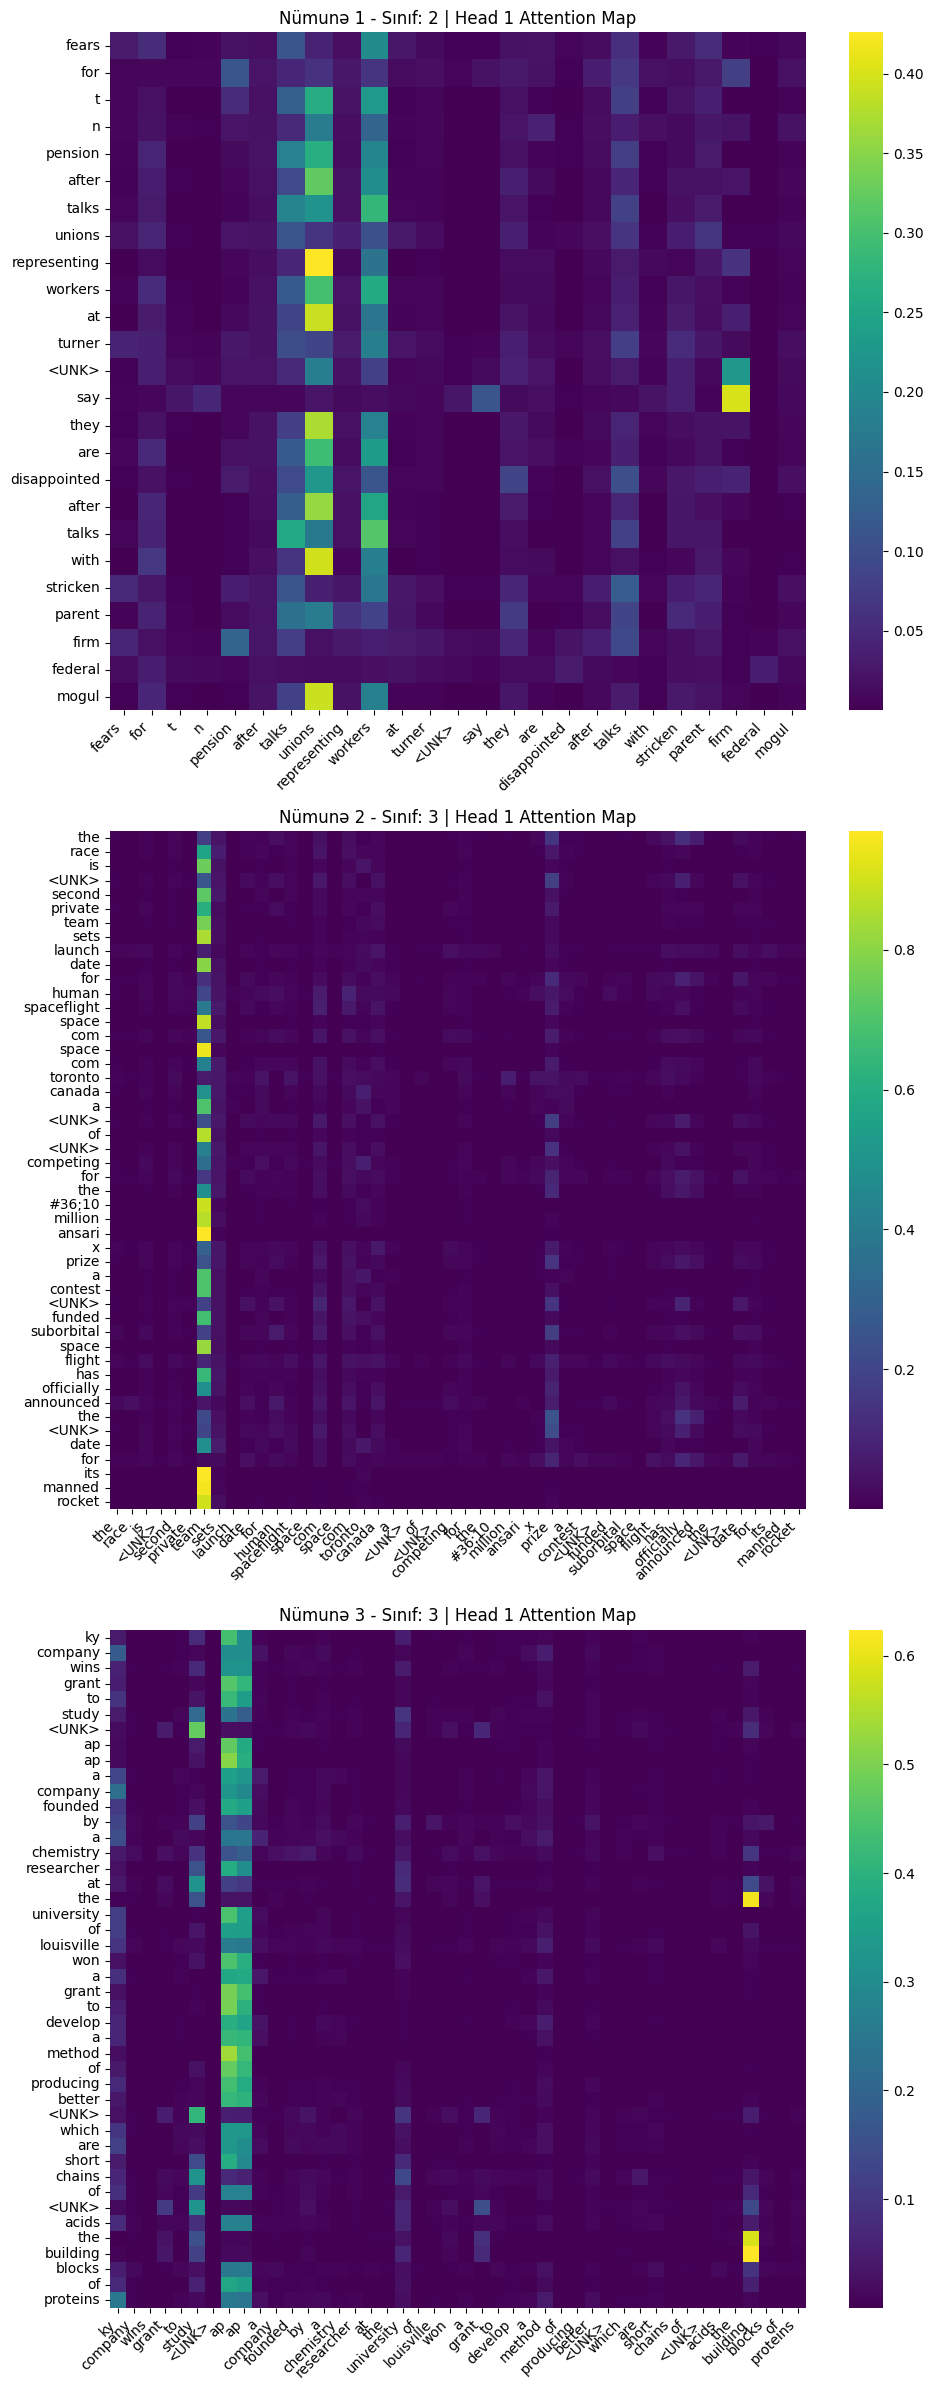

In [ ]:
def plot_attention_maps(model, dataset, vocab, num_samples=3):
    model.eval()
    fig, axes = plt.subplots(num_samples, 1, figsize=(10, 8 * num_samples))

    for i in range(num_samples):
        token_ids, label = dataset[i]
        input_tensor = token_ids.unsqueeze(0).to(device)


        with torch.no_grad():
            _ = model(input_tensor)

        attn_weights = model.layers[0].mha.attention_weights[0, 0].cpu().numpy()


        words = [vocab.idx2word[idx.item()] for idx in token_ids if idx.item() != 0]
        trimmed_attn = attn_weights[:len(words), :len(words)]


        sns.heatmap(trimmed_attn, xticklabels=words, yticklabels=words, cmap="viridis", ax=axes[i], cbar=True)
        axes[i].set_title(f"Nümunə {i+1} - Sınıf: {label.item()} | Head 1 Attention Map")
        axes[i].set_xticklabels(words, rotation=45, ha="right")

    plt.tight_layout()
    plt.show()

plot_attention_maps(transformer_model, test_dataset, vocab, num_samples=3)

In [ ]:
test_sentences = [
    {
        "text": "The football coach announced the starting lineup for the upcoming world cup tournament.",
        "real_category": "Sports"
    },
    {
        "text": "Tech giants are investing billions into artificial intelligence, new microchips, and cloud software.",
        "real_category": "Sci/Tech"
    },
    {
        "text": "Shares of the company fell drastically after the fiscal report showed a major drop in quarterly revenue.",
        "real_category": "Business"
    },
    {
        "text": "The president and foreign ministers met at the international summit to discuss trade agreements and border security.",
        "real_category": "World"
    }
]

idx_to_class_name = {0: "World", 1: "Sports", 2: "Business", 3: "Sci/Tech"}

def run_automated_test(transformer_model, gru_model, vocab, sentences, max_len=64):

    transformer_model.eval()
    gru_model.eval()

    print("=" * 85)
    print(f"{'XƏBƏR MƏTNİ':<45} | {'REAL':<10} | {'TRANSFORMER':<12} | {'GRU':<10}")
    print("=" * 85)

    with torch.no_grad():
        for item in sentences:
            text = item["text"]
            real_cat = item["real_category"]

            token_ids = vocab.numericalize(text)[:max_len]
            if len(token_ids) < max_len:
                token_ids += [vocab.word2idx["<PAD>"]] * (max_len - len(token_ids))

            input_tensor = torch.tensor(token_ids).unsqueeze(0).to(device)


            transformer_out = transformer_model(input_tensor)
            transformer_pred_idx = torch.argmax(transformer_out, dim=1).item()
            transformer_pred = idx_to_class_name[transformer_pred_idx]

            gru_out = gru_model(input_tensor)
            gru_pred_idx = torch.argmax(gru_out, dim=1).item()
            gru_pred = idx_to_class_name[gru_pred_idx]

            short_text = text if len(text) < 42 else text[:42] + "..."

            print(f"{short_text:<45} | {real_cat:<10} | {transformer_pred:<12} | {gru_pred:<10}")

    print("=" * 85)

run_automated_test(transformer_model, gru_model, vocab, test_sentences)

XƏBƏR MƏTNİ                                   | REAL       | TRANSFORMER  | GRU       
The football coach announced the starting ... | Sports     | Sports       | Sports    
Tech giants are investing billions into ar... | Sci/Tech   | Sci/Tech     | Sci/Tech  
Shares of the company fell drastically aft... | Business   | Business     | Business  
The president and foreign ministers met at... | World      | World        | World     
